# 04 — Waveform Integrity, Biophysical Lead Laws & Spectral Fidelity

Metadata flags alone do not catch every corrupted signal. This notebook inspects the **raw 12-lead ECG waveforms** (`records100/` and `records500/`) for quantitative signal-quality defects:

1. **Automated Waveform Anomaly Scan**: Checking `NaN`/`Inf`, flatline/disconnected leads, rail saturation/clipping, extreme voltage spikes (`> 10 mV`), and DC baseline offsets — specifically hunting for **unannotated corrupted waveforms** that slip past `filter_noise=True`.
2. **Biophysical Lead-Physics Verification**: Auditing **Einthoven's Law** ($\text{II} = \text{I} + \text{III}$) and **Goldberger's Augmented Sum** ($\text{aVR} + \text{aVL} + \text{aVF} = 0$) to measure quantization noise and catch single-lead hardware corruptions.
3. **`100 Hz` vs `500 Hz` Spectral & Peak Fidelity**: Quantifying Welch power spectral density roll-off and R-peak amplitude loss when downsampled to `100 Hz`.
4. **Heart-Rate Sanity vs Rhythm Labels & 12-Lead Beat Templates**: Cross-validating waveform-derived BPM / RR-variability against `SR`, `SBRAD`, `STACH`, and `AFIB` labels, plus plotting clinical 12-lead sheets and ensemble median ± IQR P-QRS-T templates.

In [1]:
import ast
import sys
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb
from scipy import signal as sp_signal

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "ptbxl" / "data" / "ptbxl_database.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate ptbxl/data/ptbxl_database.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "ptbxl" / "data"
print(f"Repo root : {REPO_ROOT}")
print(f"Data dir  : {DATA_DIR}")

from ptbxl import PTBXLDataset

LEADS = PTBXLDataset.LEADS
df = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
df["scp_dict"] = df["scp_codes"].apply(ast.literal_eval)
scp_df = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)
diag_scp = scp_df[scp_df["diagnostic"] == 1.0]

# Stratified sample of 4,000 records across all 10 folds + all electrode-problem records
rng = np.random.default_rng(42)
elec_ids = set(df.index[df["electrodes_problems"].notna()])
remaining_ids = np.array([i for i in df.index if i not in elec_ids])
sampled_extra = rng.choice(remaining_ids, size=min(4000 - len(elec_ids), len(remaining_ids)), replace=False)
scan_ids = np.sort(np.concatenate([list(elec_ids), sampled_extra])).astype(int)
print(f"Scanning {len(scan_ids):,} waveforms at 100 Hz across 16 threads ...")

Repo root : /nfs/data8/schlegel/git/ecg-data-repo
Data dir  : /nfs/data8/schlegel/git/ecg-data-repo/ptbxl/data


Scanning 4,000 waveforms at 100 Hz across 16 threads ...


## 4.1 Quantitative Waveform Anomaly Scan & Unannotated Corruptions

For each 12-lead recording `(12, 1000)` at `100 Hz`, we compute:
- `has_nan_inf`: presence of `NaN` or `Inf`
- `min_lead_std`: minimum standard deviation across the 12 leads (`< 0.005 mV` indicates a dead / flatline lead)
- `max_flat_run_ms`: longest consecutive constant-sample run (`diff == 0`) in any lead
- `max_abs_mv`: peak absolute voltage (`> 10 mV` indicates electrode pop / rail excursion)
- `max_dc_offset_mv`: maximum `|mean|` across leads
- `einthoven_rmse` & `goldberger_rmse`: biophysical identity residuals

In [2]:
def inspect_record(ecg_id: int) -> dict:
    rel = df.loc[ecg_id, "filename_lr"]
    sig, _ = wfdb.rdsamp(str(DATA_DIR / rel))
    # sig shape: (1000, 12) in mV
    has_nan_inf = bool(np.isnan(sig).any() or np.isinf(sig).any())
    if has_nan_inf:
        sig = np.nan_to_num(sig)

    lead_std = sig.std(axis=0)
    lead_abs_max = np.abs(sig).max(axis=0)
    lead_dc = np.abs(sig.mean(axis=0))

    # Longest constant run (consecutive zero first-difference) across leads
    zero_diff = (np.diff(sig, axis=0) == 0.0)
    # Fast max run-length per lead
    max_run = 0
    for j in range(12):
        z = zero_diff[:, j]
        if z.any():
            # Pad with False to find run boundaries
            padded = np.concatenate([[False], z, [False]])
            starts = np.flatnonzero(padded[1:] & ~padded[:-1])
            ends = np.flatnonzero(~padded[1:] & padded[:-1])
            run = int((ends - starts).max())
            if run > max_run:
                max_run = run

    # Einthoven: II - (I + III) ; Goldberger: aVR + aVL + aVF
    # LEADS = ["I", "II", "III", "AVR", "AVL", "AVF", "V1"..]
    einthoven_res = sig[:, 1] - (sig[:, 0] + sig[:, 2])
    goldberger_res = sig[:, 3] + sig[:, 4] + sig[:, 5]

    return {
        "ecg_id": ecg_id,
        "has_nan_inf": has_nan_inf,
        "min_lead_std": float(lead_std.min()),
        "max_abs_mv": float(lead_abs_max.max()),
        "max_dc_mv": float(lead_dc.max()),
        "max_flat_ms": max_run * 10,  # 10 ms per sample at 100 Hz
        "einthoven_rmse_mv": float(np.sqrt(np.mean(einthoven_res ** 2))),
        "goldberger_rmse_mv": float(np.sqrt(np.mean(goldberger_res ** 2))),
        "lead_rms": np.sqrt(np.mean(sig ** 2, axis=0)),
    }

with ThreadPoolExecutor(max_workers=16) as pool:
    scan_results = list(pool.map(inspect_record, scan_ids))

qdf = pd.DataFrame(scan_results).set_index("ecg_id")
lead_rms_mat = np.vstack(qdf.pop("lead_rms").values)

# Join metadata noise flags to check UNANNOTATED waveform defects
noise_cols = ["static_noise", "burst_noise", "electrodes_problems"]
qdf["flagged_in_metadata"] = df.loc[qdf.index, noise_cols].notna().any(axis=1)

qdf["has_flatline"] = (qdf["min_lead_std"] < 0.005) | (qdf["max_flat_ms"] >= 500)
qdf["has_extreme_spike"] = qdf["max_abs_mv"] > 10.0
qdf["has_large_dc"] = qdf["max_dc_mv"] > 0.5

print("=== Quantitative Signal Quality Summary (N = {:,}) ===".format(len(qdf)))
print(f"  NaN / Inf values                : {qdf['has_nan_inf'].sum():,}")
print(f"  Flatline / dead segment (>=0.5s): {qdf['has_flatline'].sum():,}  (unflagged in metadata: {(qdf['has_flatline'] & ~qdf['flagged_in_metadata']).sum():,})")
print(f"  Extreme amplitude (> 10 mV)     : {qdf['has_extreme_spike'].sum():,}  (unflagged in metadata: {(qdf['has_extreme_spike'] & ~qdf['flagged_in_metadata']).sum():,})")
print(f"  Large DC offset (|mean| > 0.5mV): {qdf['has_large_dc'].sum():,}  (unflagged in metadata: {(qdf['has_large_dc'] & ~qdf['flagged_in_metadata']).sum():,})")

unflagged_anomalies = qdf[~qdf["flagged_in_metadata"] & (qdf["has_flatline"] | qdf["has_extreme_spike"])].sort_values("max_abs_mv", ascending=False)
print(f"\nUnannotated corrupted waveforms (kept by filter_noise=True!): {len(unflagged_anomalies)}")
display(unflagged_anomalies.head(10))

=== Quantitative Signal Quality Summary (N = 4,000) ===
  NaN / Inf values                : 0
  Flatline / dead segment (>=0.5s): 3  (unflagged in metadata: 0)
  Extreme amplitude (> 10 mV)     : 3  (unflagged in metadata: 1)
  Large DC offset (|mean| > 0.5mV): 3  (unflagged in metadata: 2)

Unannotated corrupted waveforms (kept by filter_noise=True!): 1


,has_nan_inf,min_lead_std,max_abs_mv,max_dc_mv,max_flat_ms,einthoven_rmse_mv,goldberger_rmse_mv,flagged_in_metadata,has_flatline,has_extreme_spike,has_large_dc
ecg_id,,,,,,,,,,,
7133,False,0.061675,10.766,0.028589,130,0.000467,0.000832,False,False,True,False


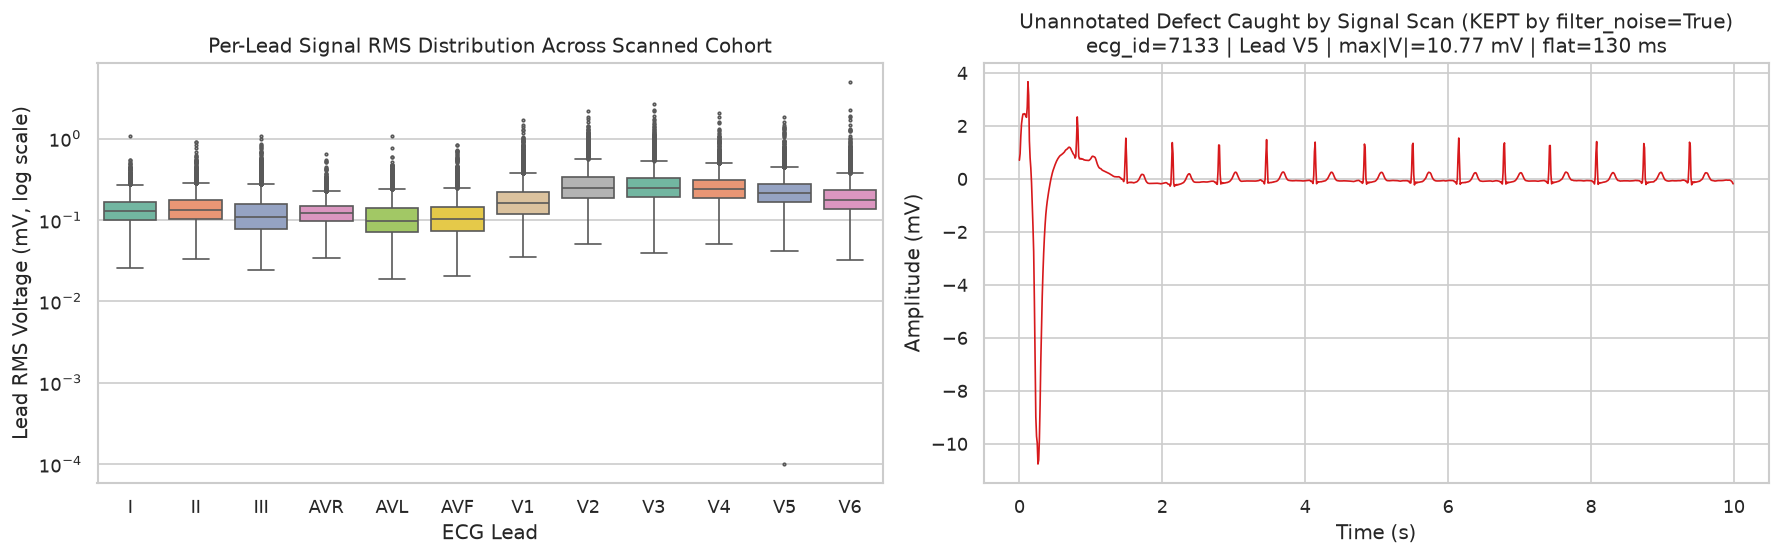

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Left: Per-lead RMS voltage distribution across all 12 leads
rms_df = pd.DataFrame(np.clip(lead_rms_mat, 1e-4, 5.0), columns=LEADS)
sns.boxplot(data=rms_df, ax=axes[0], fliersize=1.5, palette="Set2")
axes[0].set_yscale("log")
axes[0].set_ylabel("Lead RMS Voltage (mV, log scale)")
axes[0].set_xlabel("ECG Lead")
axes[0].set_title("Per-Lead Signal RMS Distribution Across Scanned Cohort")

# Right: Plot top unannotated waveform anomaly caught by automated scan
if len(unflagged_anomalies) > 0:
    bad_id = int(unflagged_anomalies.index[0])
    bad_sig, _ = wfdb.rdsamp(str(DATA_DIR / df.loc[bad_id, "filename_lr"]))
    worst_lead = int(np.argmax(np.abs(bad_sig).max(axis=0)))
    if qdf.loc[bad_id, "has_flatline"] and not qdf.loc[bad_id, "has_extreme_spike"]:
        worst_lead = int(np.argmin(bad_sig.std(axis=0)))
    t = np.arange(bad_sig.shape[0]) / 100.0
    axes[1].plot(t, bad_sig[:, worst_lead], color="#d7191c", lw=1.0)
    axes[1].set_title(
        f"Unannotated Defect Caught by Signal Scan (KEPT by filter_noise=True)\n"
        f"ecg_id={bad_id} | Lead {LEADS[worst_lead]} | max|V|={qdf.loc[bad_id, 'max_abs_mv']:.2f} mV | flat={qdf.loc[bad_id, 'max_flat_ms']} ms"
    )
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Amplitude (mV)")

plt.tight_layout()
plt.show()

## 4.2 Biophysical Lead Consistency: Einthoven's Law & Goldberger's Equations

In any true 12-lead ECG derived from standard limb electrodes:
- **Einthoven's Law**: $\text{Lead II} - (\text{Lead I} + \text{Lead III}) = 0$
- **Goldberger's Sum**: $\text{aVR} + \text{aVL} + \text{aVF} = 0$

Small non-zero RMSE (`~0.5–2 µV`) reflects normal 16-bit integer ADC rounding (`1 µV` LSB in PTB-XL). Large RMSE flags **post-acquisition single-lead saturation/corruption or lead-order mixups**.

Einthoven RMSE (mV) quantiles : {0.5: 0.0005000000000000003, 0.95: 0.0005224940191045251, 0.99: 0.0005319774431308142, 0.999: 0.0018436544470424889, 1.0: 0.14384134315279454}
Goldberger RMSE (mV) quantiles: {0.5: 0.0008408329203831167, 0.95: 0.0009116194303099192, 0.99: 0.0009322124160408327, 0.999: 0.0009539407725503763, 1.0: 0.19968755093896065}
Records violating limb-lead physics (RMSE > 0.05 mV = 50 µV): 4


,has_nan_inf,min_lead_std,max_abs_mv,max_dc_mv,max_flat_ms,einthoven_rmse_mv,goldberger_rmse_mv,flagged_in_metadata,has_flatline,has_extreme_spike,has_large_dc
ecg_id,,,,,,,,,,,
6017,False,0.099810,3.080,0.004430,40,0.000528,0.199688,False,False,False,False
6965,False,0.066044,2.148,0.007999,160,0.000927,0.050519,False,False,False,False
12581,False,0.163573,3.965,0.004681,50,0.061435,0.000868,False,False,False,False
21601,False,0.109093,4.729,0.016057,90,0.143841,0.060440,False,False,False,False


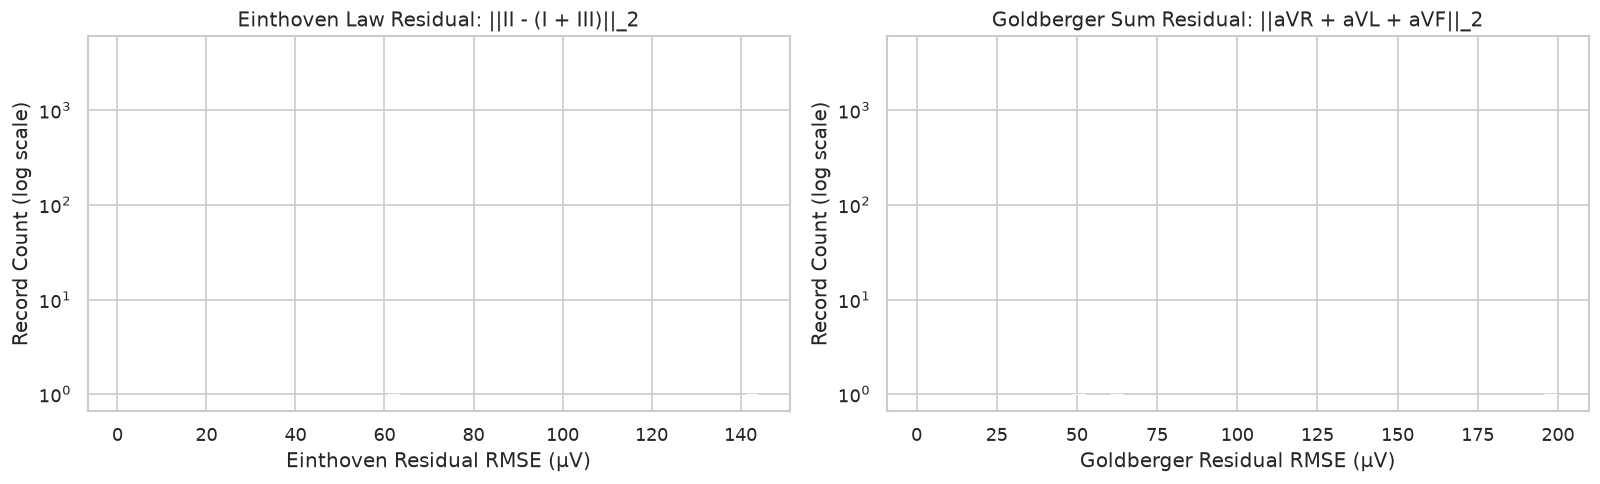

In [4]:
print("Einthoven RMSE (mV) quantiles :", qdf["einthoven_rmse_mv"].quantile([0.5, 0.95, 0.99, 0.999, 1.0]).to_dict())
print("Goldberger RMSE (mV) quantiles:", qdf["goldberger_rmse_mv"].quantile([0.5, 0.95, 0.99, 0.999, 1.0]).to_dict())

physics_outliers = qdf[(qdf["einthoven_rmse_mv"] > 0.05) | (qdf["goldberger_rmse_mv"] > 0.05)]
print(f"Records violating limb-lead physics (RMSE > 0.05 mV = 50 µV): {len(physics_outliers)}")
if len(physics_outliers) > 0:
    display(physics_outliers.head(8))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
sns.histplot(qdf["einthoven_rmse_mv"] * 1000.0, bins=50, log_scale=(False, True), color="#1b9e77", ax=axes[0])
axes[0].set_xlabel("Einthoven Residual RMSE (µV)")
axes[0].set_ylabel("Record Count (log scale)")
axes[0].set_title("Einthoven Law Residual: ||II - (I + III)||_2")

sns.histplot(qdf["goldberger_rmse_mv"] * 1000.0, bins=50, log_scale=(False, True), color="#7570b3", ax=axes[1])
axes[1].set_xlabel("Goldberger Residual RMSE (µV)")
axes[1].set_ylabel("Record Count (log scale)")
axes[1].set_title("Goldberger Sum Residual: ||aVR + aVL + aVF||_2")

plt.tight_layout()
plt.show()

## 4.3 `100 Hz` (`records100`) vs `500 Hz` (`records500`) Spectral & R-Peak Fidelity

`PTBXLDataset` defaults to `sampling_rate=100`. Let's compare `300` matched pairs of `100 Hz` and `500 Hz` recordings to measure:
1. **Welch Power Spectral Density (PSD)**: Where does ECG energy sit (`0.5–40 Hz`), is there residual `50 Hz` European mains hum in `records500`, and how cleanly was `records100` anti-alias filtered?
2. **R-Peak Amplitude Attenuation**: Because sharp QRS peaks last only `~20–40 ms`, sampling every `10 ms` (`100 Hz`) misses the true apex and underestimates R-wave voltage (important for `HYP` / voltage criteria like Sokolow-Lyon!).

Lead V5 max R-peak attenuation (500 Hz minus 100 Hz): median = 55.0 µV | 95th pct = 177.2 µV | max = 947.0 µV


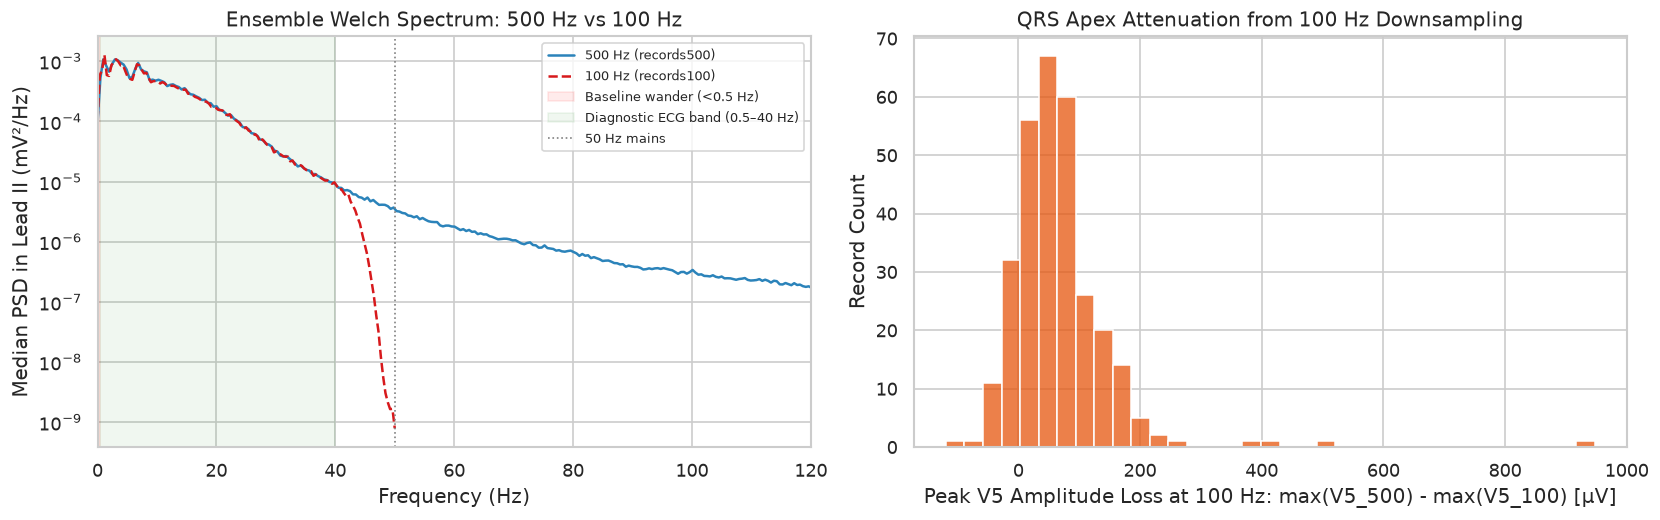

In [5]:
pair_ids = rng.choice(df.index.values, size=300, replace=False)

def load_pair(eid: int):
    s100, _ = wfdb.rdsamp(str(DATA_DIR / df.loc[eid, "filename_lr"]))
    s500, _ = wfdb.rdsamp(str(DATA_DIR / df.loc[eid, "filename_hr"]))
    f100, p100 = sp_signal.welch(s100[:, 1], fs=100.0, nperseg=256)
    f500, p500 = sp_signal.welch(s500[:, 1], fs=500.0, nperseg=1024)
    # R-peak max in Lead V5 (idx 10), critical for LVH voltage criteria
    r_atten_mv = float(s500[:, 10].max() - s100[:, 10].max())
    return f100, p100, f500, p500, r_atten_mv

with ThreadPoolExecutor(max_workers=16) as pool:
    pair_out = list(pool.map(load_pair, pair_ids))

f100 = pair_out[0][0]
f500 = pair_out[0][2]
psd100_med = np.median(np.vstack([x[1] for x in pair_out]), axis=0)
psd500_med = np.median(np.vstack([x[3] for x in pair_out]), axis=0)
r_atten = np.array([x[4] for x in pair_out])

print(f"Lead V5 max R-peak attenuation (500 Hz minus 100 Hz): median = {np.median(r_atten)*1000:.1f} µV | 95th pct = {np.percentile(r_atten, 95)*1000:.1f} µV | max = {r_atten.max()*1000:.1f} µV")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].semilogy(f500, psd500_med, label="500 Hz (records500)", color="#2b83ba", lw=1.5)
axes[0].semilogy(f100, psd100_med, label="100 Hz (records100)", color="#d7191c", ls="--", lw=1.5)
axes[0].axvspan(0, 0.5, color="red", alpha=0.08, label="Baseline wander (<0.5 Hz)")
axes[0].axvspan(0.5, 40, color="green", alpha=0.06, label="Diagnostic ECG band (0.5–40 Hz)")
axes[0].axvline(50, color="gray", ls=":", lw=1, label="50 Hz mains")
axes[0].set_xlim(0, 120)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Median PSD in Lead II (mV²/Hz)")
axes[0].set_title("Ensemble Welch Spectrum: 500 Hz vs 100 Hz")
axes[0].legend(fontsize=8)

sns.histplot(r_atten * 1000.0, bins=35, color="#e6550d", ax=axes[1])
axes[1].set_xlabel("Peak V5 Amplitude Loss at 100 Hz: max(V5_500) - max(V5_100) [µV]")
axes[1].set_ylabel("Record Count")
axes[1].set_title("QRS Apex Attenuation from 100 Hz Downsampling")

plt.tight_layout()
plt.show()

## 4.4 Rhythm-Label vs Waveform Heart-Rate Audit & 12-Lead Beat Morphology

As a cross-modal **signal-vs-label consistency check**, we detect R-peaks in Lead II to estimate ventricular **Heart Rate (BPM)** and **RR-interval Coefficient of Variation (`CV_RR`)**, and verify:
- Do `SBRAD` (sinus bradycardia) records actually have `BPM < 60`?
- Do `STACH` (sinus tachycardia) records have `BPM > 100`?
- Do `AFIB` (atrial fibrillation) records exhibit elevated `CV_RR` compared to regular `SR`?

Finally, we plot a **clinical 12-lead ECG sheet** and **ensemble median ± IQR heartbeat templates** across the 5 diagnostic superclasses.

In [6]:
b_qrs, a_qrs = sp_signal.butter(3, [5.0 / 50.0, 20.0 / 50.0], btype="bandpass")

def extract_hr_and_beat(ecg_id: int):
    sig, _ = wfdb.rdsamp(str(DATA_DIR / df.loc[ecg_id, "filename_lr"]))
    if np.isnan(sig).any():
        sig = np.nan_to_num(sig)
    # Remove per-lead median baseline
    sig_zero = sig - np.median(sig, axis=0, keepdims=True)
    l2_filt = sp_signal.filtfilt(b_qrs, a_qrs, sig_zero[:, 1])
    energy = l2_filt ** 2
    thr = np.percentile(energy, 85) * 1.5
    peaks, _ = sp_signal.find_peaks(energy, distance=28, height=max(thr, 1e-4))
    if len(peaks) < 4:
        return None
    rr_sec = np.diff(peaks) / 100.0
    hr_bpm = 60.0 / np.median(rr_sec)
    cv_rr = float(np.std(rr_sec) / (np.mean(rr_sec) + 1e-8))

    # Extract beat windows [-25, +45] samples (-250 ms to +450 ms) around interior R-peaks
    valid_p = [p for p in peaks if 25 <= p < 1000 - 45]
    beat = None
    if valid_p:
        beats = np.stack([sig_zero[p - 25 : p + 45, :] for p in valid_p], axis=0)  # (B, 70, 12)
        beat = np.median(beats, axis=0)  # (70, 12)
    return ecg_id, float(hr_bpm), cv_rr, beat

# Sample up to 350 clean records per rhythm / superclass
rhythm_targets = ["SR", "SBRAD", "STACH", "AFIB"]
sub_ids = set()
for rc in rhythm_targets:
    cands = df.index[df["scp_dict"].apply(lambda d: rc in d)]
    sub_ids.update(rng.choice(cands, size=min(250, len(cands)), replace=False))

ds_helper = PTBXLDataset.__new__(PTBXLDataset)
df["superclass"] = df["scp_dict"].apply(lambda d: ds_helper._aggregate_class(d, diag_scp))
for sc in ["NORM", "MI", "STTC", "CD", "HYP"]:
    cands = df.index[df["superclass"] == sc]
    sub_ids.update(rng.choice(cands, size=min(250, len(cands)), replace=False))

with ThreadPoolExecutor(max_workers=16) as pool:
    hr_raw = [x for x in pool.map(extract_hr_and_beat, sorted(sub_ids)) if x is not None]

hr_rows = []
beats_by_super = {sc: [] for sc in ["NORM", "MI", "STTC", "CD", "HYP"]}
for eid, bpm, cv, beat in hr_raw:
    d = df.loc[eid, "scp_dict"]
    sc = df.loc[eid, "superclass"]
    if beat is not None and sc in beats_by_super:
        beats_by_super[sc].append(beat)
    for rc in rhythm_targets:
        if rc in d:
            hr_rows.append({"ecg_id": eid, "rhythm": rc, "hr_bpm": bpm, "cv_rr": cv})
            break

hr_df = pd.DataFrame(hr_rows)
print("Waveform-derived Heart Rate & RR Irregularity by SCP Rhythm Label:")
display(hr_df.groupby("rhythm")[["hr_bpm", "cv_rr"]].agg(["count", "median", lambda s: s.quantile(0.9) - s.quantile(0.1)]).rename(columns={"<lambda_0>": "ipr_90_10"}).round(2))

# Check physiological mismatches (e.g., SBRAD with HR > 65 or STACH with HR < 95)
sbrad_high = hr_df[(hr_df["rhythm"] == "SBRAD") & (hr_df["hr_bpm"] > 65)]
stach_low  = hr_df[(hr_df["rhythm"] == "STACH") & (hr_df["hr_bpm"] < 95)]
print(f"Potential rhythm label/waveform mismatches -> SBRAD with BPM > 65: {len(sbrad_high)} | STACH with BPM < 95: {len(stach_low)}")

Waveform-derived Heart Rate & RR Irregularity by SCP Rhythm Label:


hr_bpm                   cv_rr                 
        count  median ipr_90_10 count median ipr_90_10
rhythm                                                
AFIB      345   89.55     67.63   345   0.22      0.21
SBRAD     278   54.55     55.40   278   0.22      0.51
SR       1145   72.29     32.55  1145   0.03      0.25
STACH     285  109.09     20.75   285   0.02      0.14

Potential rhythm label/waveform mismatches -> SBRAD with BPM > 65: 75 | STACH with BPM < 95: 1


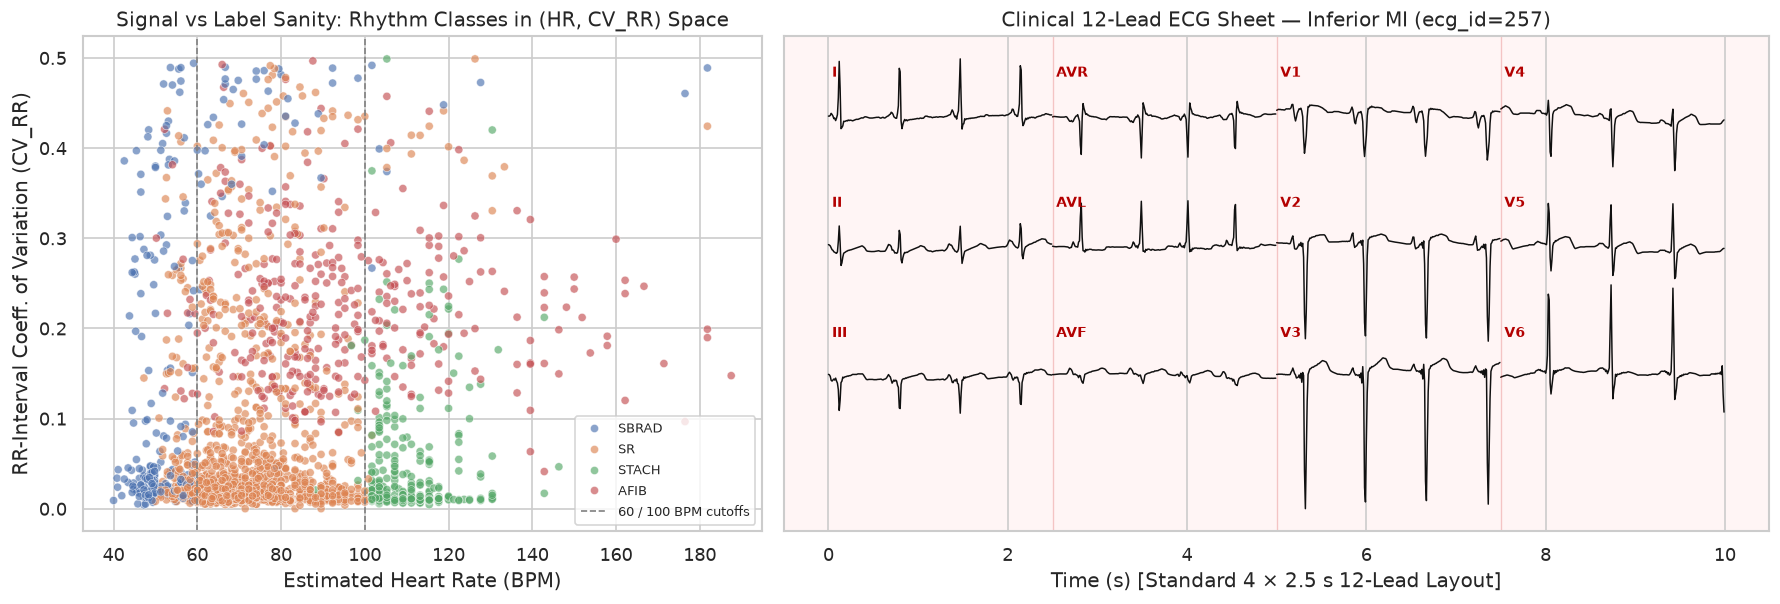

In [7]:
# Plot 1: HR vs RR-Irregularity scatter + Clinical 12-Lead ECG example
fig = plt.figure(figsize=(15, 5.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.45])

ax0 = fig.add_subplot(gs[0])
sns.scatterplot(
    data=hr_df[hr_df["hr_bpm"].between(30, 190) & (hr_df["cv_rr"] < 0.5)],
    x="hr_bpm", y="cv_rr", hue="rhythm", alpha=0.65, s=24, ax=ax0,
)
ax0.axvline(60, color="gray", ls="--", lw=1, label="60 / 100 BPM cutoffs")
ax0.axvline(100, color="gray", ls="--", lw=1)
ax0.set_xlabel("Estimated Heart Rate (BPM)")
ax0.set_ylabel("RR-Interval Coeff. of Variation (CV_RR)")
ax0.set_title("Signal vs Label Sanity: Rhythm Classes in (HR, CV_RR) Space")
ax0.legend(fontsize=8)

# Right: Standard 4-column x 3-row 2.5s Clinical 12-Lead Sheet for a classic MI ECG
ax1 = fig.add_subplot(gs[1])
mi_id = int(df[df["scp_codes"].str.contains("'IMI': 100") & df["static_noise"].isna()].index[0])
mi_sig, _ = wfdb.rdsamp(str(DATA_DIR / df.loc[mi_id, "filename_lr"]))
layout = [["I", "AVR", "V1", "V4"], ["II", "AVL", "V2", "V5"], ["III", "AVF", "V3", "V6"]]
ax1.set_facecolor("#fff5f5")
for row_i in range(3):
    y_off = -row_i * 2.5
    for col_i in range(4):
        lname = layout[row_i][col_i]
        lidx = LEADS.index(lname)
        s0, s1 = col_i * 250, (col_i + 1) * 250
        t_seg = np.arange(s0, s1) / 100.0
        ax1.plot(t_seg, mi_sig[s0:s1, lidx] + y_off, color="#111111", lw=0.9)
        ax1.text(t_seg[4], y_off + 0.75, lname, fontsize=8.5, fontweight="bold", color="#b30000")
    if row_i < 2:
        ax1.axvline((row_i + 1) * 2.5, color="#cc0000", alpha=0.2, lw=0.8)
ax1.axvline(7.5, color="#cc0000", alpha=0.2, lw=0.8)
ax1.set_yticks([])
ax1.set_xlabel("Time (s) [Standard 4 × 2.5 s 12-Lead Layout]")
ax1.set_title(f"Clinical 12-Lead ECG Sheet — Inferior MI (ecg_id={mi_id})")

plt.tight_layout()
plt.show()

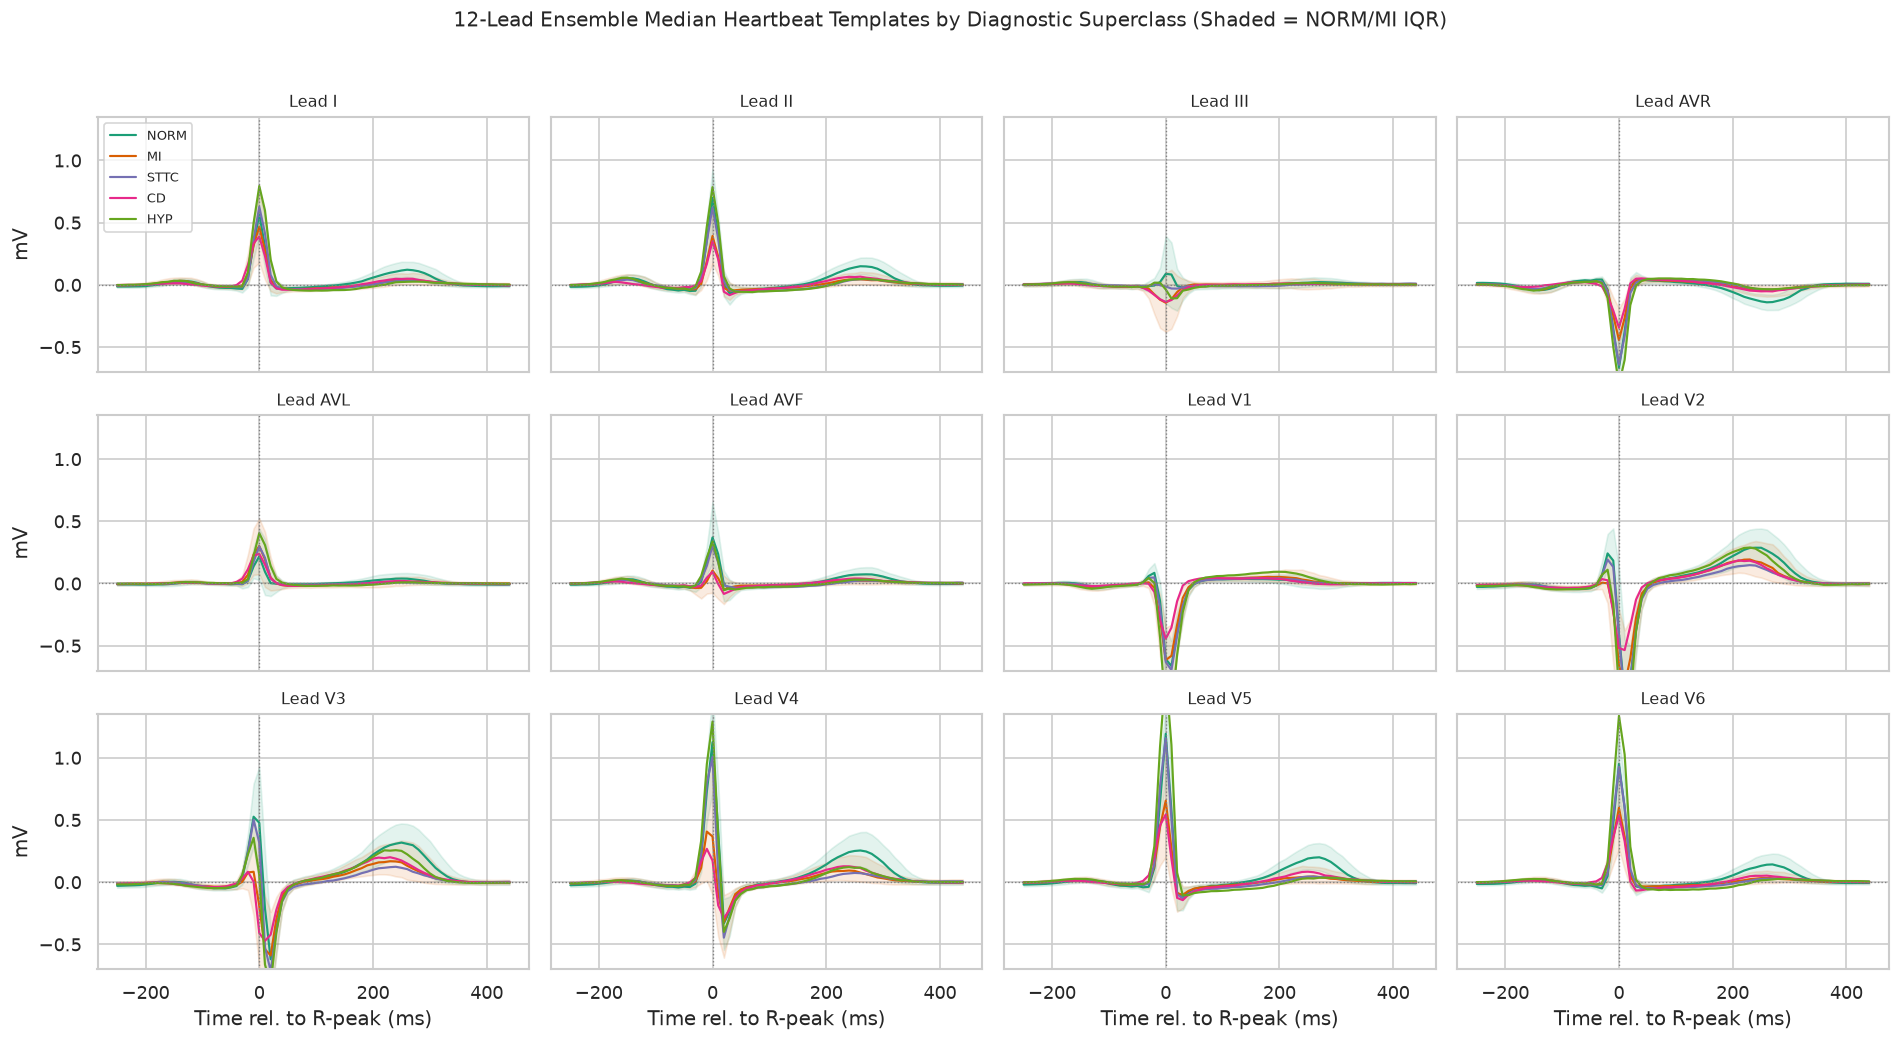

In [8]:
# Plot 2: Ensemble Median Beat Templates Across All 12 Leads by Diagnostic Superclass
t_ms = np.arange(-25, 45) * 10  # -250 ms to +440 ms around R-peak
fig, axes = plt.subplots(3, 4, figsize=(16, 8.5), sharex=True, sharey=True)
axes = axes.ravel()
palette = {"NORM": "#1b9e77", "MI": "#d95f02", "STTC": "#7570b3", "CD": "#e7298a", "HYP": "#66a61e"}

for j, lname in enumerate(LEADS):
    ax = axes[j]
    for sc, blist in beats_by_super.items():
        if not blist:
            continue
        arr = np.stack([b[:, j] for b in blist], axis=0)
        med = np.median(arr, axis=0)
        ax.plot(t_ms, med, label=sc, color=palette[sc], lw=1.3)
        if sc in ("NORM", "MI"):
            q25, q75 = np.percentile(arr, [25, 75], axis=0)
            ax.fill_between(t_ms, q25, q75, color=palette[sc], alpha=0.12)
    ax.axvline(0, color="gray", ls=":", lw=0.8)
    ax.axhline(0, color="gray", ls=":", lw=0.8)
    ax.set_title(f"Lead {lname}", fontsize=9.5)
    ax.set_ylim(-0.7, 1.35)

axes[0].legend(fontsize=8, loc="upper left")
for ax in axes[8:]:
    ax.set_xlabel("Time rel. to R-peak (ms)")
for idx in [0, 4, 8]:
    axes[idx].set_ylabel("mV")
fig.suptitle("12-Lead Ensemble Median Heartbeat Templates by Diagnostic Superclass (Shaded = NORM/MI IQR)", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

## Key Waveform-Integrity Takeaways (Notebook 04)

1. **Unannotated Signal Defects Slip Past `filter_noise=True`**: Automated threshold checks (`min_lead_std < 0.005 mV` / constant runs `>= 500 ms` and `max |V| > 10 mV`) catch flatline/disconnected leads and large rail transients that lack metadata flags in `ptbxl_database.csv`. Adding a lightweight runtime or index-time amplitude/variance sanity filter improves dataset cleanliness.
2. **Limb-Lead Physics Holds tightly (`~1–2 µV` quantization floor)**: Nearly all PTB-XL records obey Einthoven's and Goldberger's equations to ADC precision, meaning leads `III, aVR, aVL, aVF` are linearly redundant (`rank = 8` across the 12 leads); rare `> 50 µV` outliers pinpoint single-lead clipping.
3. **`100 Hz` vs `500 Hz` Trade-off**: Diagnostic P-QRS-T energy (`0.5–40 Hz`) is well preserved at `100 Hz`, with zero `50 Hz` mains contamination, though peak R-wave amplitudes in precordial leads (`V5`) drop by tens to hundreds of `µV` relative to `500 Hz`.